# Projeto – Fundamentos de Machine Learning
___

O objetivo deste projeto é colocar em prática os conceitos estudados em sala sobre:

* Pré-processamento de dados
* Aprendizado supervisionado e não supervisionado
* Regressão, classificação e clusterização
* Boas práticas em Machine Learning (overfitting, regularização, PCA, evitar vazamento de informações, tratamento de classes desbalanceadas, etc.)
___
## Tarefa
___

Cada aluno deverá escolher um dataset de sua preferência (ex.: Kaggle, UCI Machine Learning Repository, IBGE, dados sintéticos gerados com IA, entre outros) e desenvolver um projeto de Machine Learning, contendo as seguintes etapas:

1. Descrição do problema a ser resolvido (ex.: previsão, classificação, agrupamento).
2. Pré-processamento dos dados: tratamento de valores ausentes, normalização/transformação, codificação de variáveis, análise exploratória.
3. Definição da tarefa de aprendizado: supervisionado ou não supervisionado.
4. Construção do modelo: escolha de algoritmos adequados (regressão, classificação, clusterização, etc.).
5. Avaliação do modelo: utilização de métricas apropriadas ao problema.
6. Aplicação de boas práticas conforme a necessidade:
    * Evitar overfitting
    * Validação adequada
    * Regularização, quando necessário
    * Tratamento de classes desbalanceadas
    * Evitar vazamento de informações
___
## Observações
___

* O tema e o dataset são de livre escolha de cada aluno.
* O projeto pode ser entregue em formato de notebook (Jupyter/Google Colab) com explicações e códigos ou PDF.
* Lembre-se: mais importante do que a complexidade do modelo é a aplicação correta dos fundamentos que vimos na disciplina.

In [27]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Importações das funções específicas do scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [9]:
ARQUIVOML = 'bank-customer-churn-prediction.csv'
df = pd.read_csv(ARQUIVOML, encoding='utf-8-sig')

In [10]:
display(df.head())

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## Tipos de dados

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       10000 non-null  int64  
 1   credit_score      10000 non-null  int64  
 2   country           10000 non-null  str    
 3   gender            10000 non-null  str    
 4   age               10000 non-null  int64  
 5   tenure            10000 non-null  int64  
 6   balance           10000 non-null  float64
 7   products_number   10000 non-null  int64  
 8   credit_card       10000 non-null  int64  
 9   active_member     10000 non-null  int64  
 10  estimated_salary  10000 non-null  float64
 11  churn             10000 non-null  int64  
dtypes: float64(2), int64(8), str(2)
memory usage: 937.6 KB


## Checagem de nulos

In [13]:
df.isna().sum()

customer_id         0
credit_score        0
country             0
gender              0
age                 0
tenure              0
balance             0
products_number     0
credit_card         0
active_member       0
estimated_salary    0
churn               0
dtype: int64

In [12]:
df['churn'].value_counts(normalize=True)


churn
0    0.7963
1    0.2037
Name: proportion, dtype: float64

Cerca de 20% dos clientes abandonaram o banco. As classes são **desbalanceadas**.

## Renomeando rótulos

In [17]:
df.columns = [
    'id_cliente', 
    'score_credito', 
    'pais', 
    'genero', 
    'idade', 
    'tempo_contrato', 
    'saldo', 
    'quantidade_produtos', 
    'cartao_credito', 
    'membro_ativo', 
    'salario_estimado', 
    'rotatividade'
]

In [18]:
df.head()

,id_cliente,score_credito,pais,genero,idade,tempo_contrato,saldo,quantidade_produtos,cartao_credito,membro_ativo,salario_estimado,rotatividade
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [25]:
df.describe()

,id_cliente,score_credito,idade,tempo_contrato,saldo,quantidade_produtos,cartao_credito,membro_ativo,salario_estimado,rotatividade
count,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


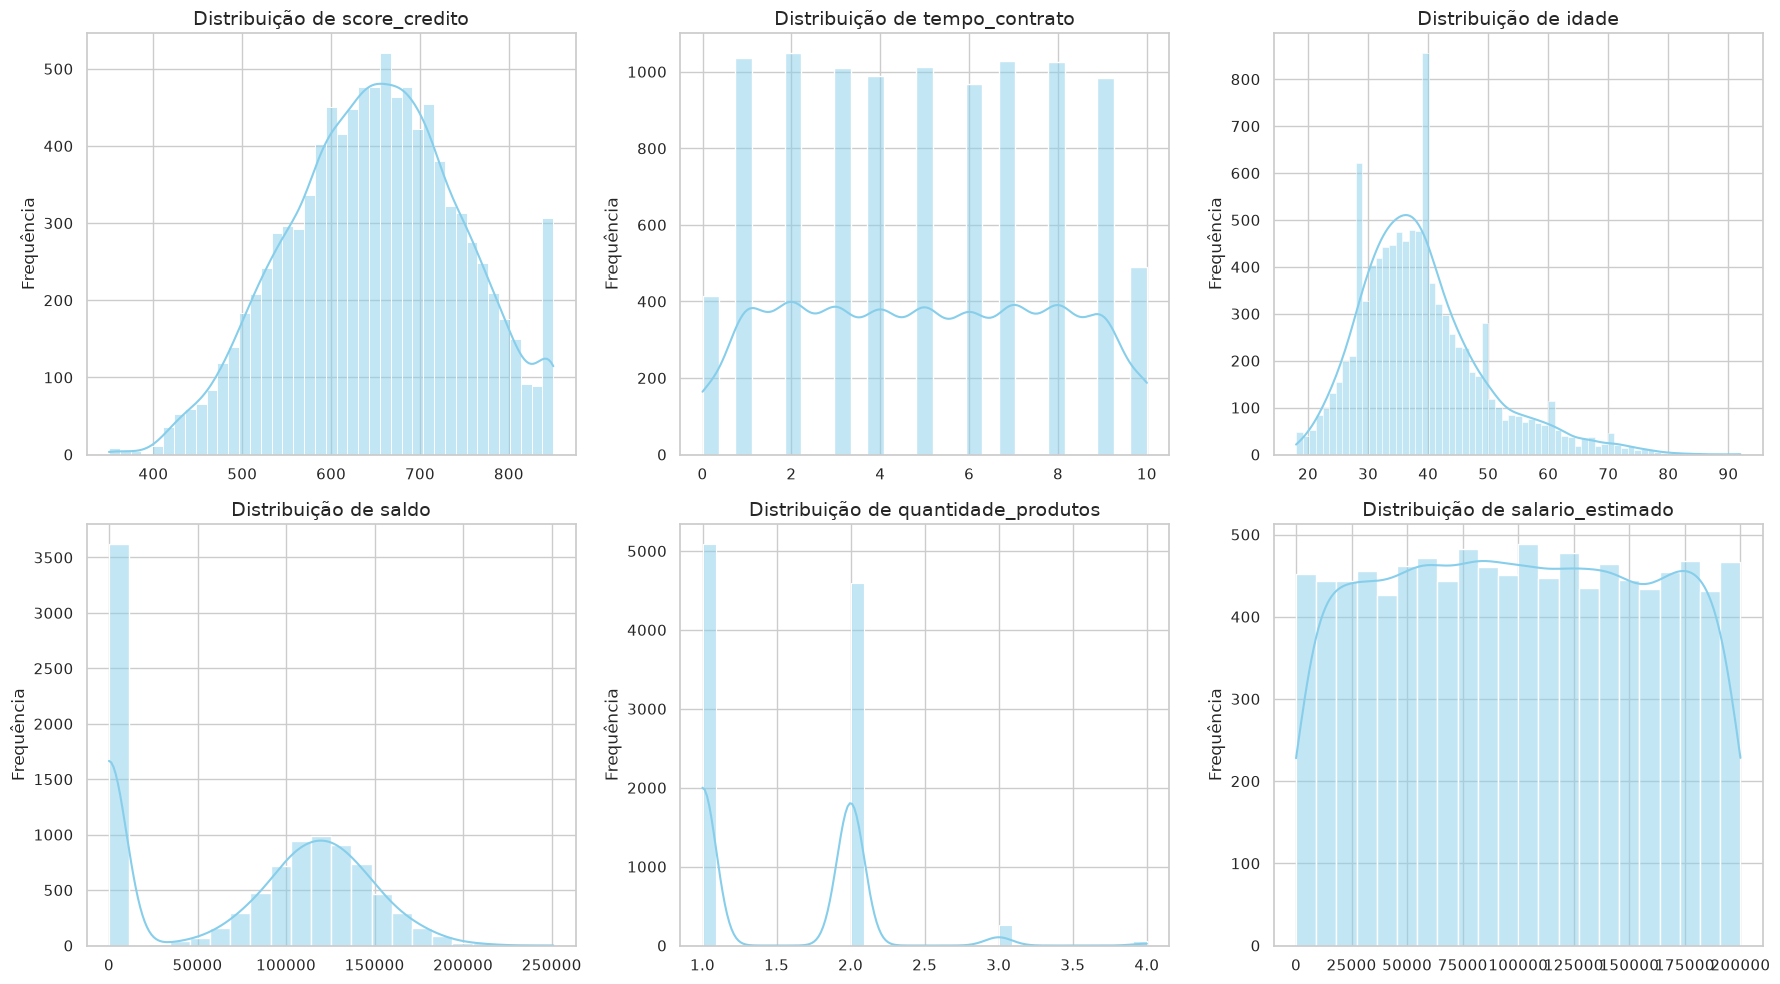

In [28]:
variaveis_quantitativas = ['score_credito', 'tempo_contrato', 'idade', 'saldo', 'quantidade_produtos', 'salario_estimado']

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 10))
axes = axes.flatten()

for i, coluna in enumerate(variaveis_quantitativas):
    sns.histplot(
        data=df,
        x=coluna,
        kde=True,
        color="skyblue",
        ax=axes[i]
    )
    axes[i].set_title(f'Distribuição de {coluna}', fontsize=14)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Frequência')

plt.tight_layout()
plt.show()


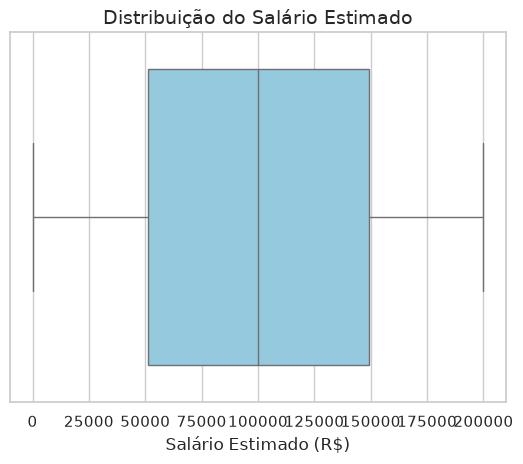

In [29]:
sns.boxplot(
    data=df,
    x='salario_estimado', 
    color="skyblue"
)
plt.title('Distribuição do Salário Estimado', fontsize=14)
plt.xlabel('Salário Estimado (R$)', fontsize=12)
plt.show()

In [21]:
treino, teste = train_test_split(df, test_size=0.2, random_state=42, stratify=df['rotatividade'])
y_treino, y_teste = treino['rotatividade'], teste['rotatividade']

In [22]:
print(f'treino: {len(treino)} clientes ({y_treino.mean():.1%} mudaram de banco)')
print(f'teste: {len(teste)} clientes ({y_teste.mean():.1%} mudaram de banco)')

treino: 8000 clientes (20.4% mudaram de banco)
teste: 2000 clientes (20.3% mudaram de banco)


In [24]:
treino.groupby('rotatividade')[['score_credito', 'tempo_contrato', 'idade', 'saldo', 'quantidade_produtos', 'salario_estimado']].mean().round(1)

,score_credito,tempo_contrato,idade,saldo,quantidade_produtos,salario_estimado
rotatividade,,,,,,
0,652.4,5.0,37.5,72554.1,1.5,99143.3
1,644.3,5.0,44.8,91337.3,1.5,102027.0
